# Bank Marketing Campaign Prediction

## Sprint 1: Data Understanding & Preprocessing

### Project Objective

The objective of this project is to build a classification solution that predicts whether a bank client will subscribe to a term deposit based on customer and campaign-related information.

### Business Objective

The prediction can help the bank:

- Reduce unnecessary telemarketing calls
- Target customers who are more likely to subscribe
- Improve campaign conversion rates
- Support data-driven marketing decisions

### Target Variable

The target variable is `y`.

- `yes` → Client subscribed to a term deposit
- `no` → Client did not subscribe to a term deposit

### Sprint 1 Goal

The goal of Sprint 1 is to understand, clean, analyze, and preprocess the raw dataset so that it becomes suitable for machine learning.

# Step 1 — Data Collection & Loading

In this step, we load the Bank Marketing dataset using Pandas.

The dataset is provided in CSV format.

We will:

- Load the training dataset
- Load the testing dataset
- Check the dataset size
- Check the column structure

**Import required libraries**

In [10]:
# Step 1: Import Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import joblib
from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_style("whitegrid")

print("All required libraries imported successfully!")

All required libraries imported successfully!


Data collection and loading

In [11]:
# Step 2: Load Dataset

possible_paths = [
    Path("../data/raw/bank_marketing.csv"),
    Path("data/raw/bank_marketing.csv")
]

data_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if data_path is None:
    raise FileNotFoundError(
        "Dataset not found. Check data/raw/bank_marketing.csv"
    )

df = pd.read_csv(data_path, sep=";")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
# View First and Last Records

print("First 5 Records:")
display(df.head())

print("\nLast 5 Records:")
display(df.tail())

First 5 Records:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no



Last 5 Records:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


In [13]:
# Dataset Information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB


In [14]:
# Statistical Summary

display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


In [15]:
# Check Data Types

print(df.dtypes)

age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object


In [16]:
# Check Missing Values

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": (
        missing_values / len(df)
    ) * 100
})

display(missing_summary)

,Missing_Count,Missing_Percentage
age,0,0.0
job,0,0.0
marital,0,0.0
education,0,0.0
default,0,0.0
balance,0,0.0
housing,0,0.0
loan,0,0.0
contact,0,0.0
day,0,0.0


In [18]:
# Check Unique Values

for column in df.columns:
    print(
        f"{column}: {df[column].nunique()} unique values"
    )

age: 77 unique values
job: 12 unique values
marital: 3 unique values
education: 4 unique values
default: 2 unique values
balance: 7168 unique values
housing: 2 unique values
loan: 2 unique values
contact: 3 unique values
day: 31 unique values
month: 12 unique values
duration: 1573 unique values
campaign: 48 unique values
pdays: 559 unique values
previous: 41 unique values
poutcome: 4 unique values
y: 2 unique values


In [19]:
# Inspect Categorical Values

categorical_columns = df.select_dtypes(
    include=["object", "str"]
).columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


job:
<ArrowStringArray>
[   'management',    'technician',  'entrepreneur',   'blue-collar',
       'unknown',       'retired',        'admin.',      'services',
 'self-employed',    'unemployed',     'housemaid',       'student']
Length: 12, dtype: str

marital:
<ArrowStringArray>
['married', 'single', 'divorced']
Length: 3, dtype: str

education:
<ArrowStringArray>
['tertiary', 'secondary', 'unknown', 'primary']
Length: 4, dtype: str

default:
<ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str

housing:
<ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str

loan:
<ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str

contact:
<ArrowStringArray>
['unknown', 'cellular', 'telephone']
Length: 3, dtype: str

month:
<ArrowStringArray>
['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'jan', 'feb', 'mar', 'apr',
 'sep']
Length: 12, dtype: str

poutcome:
<ArrowStringArray>
['unknown', 'failure', 'other', 'success']
Length: 4, dtype: str

y:
<ArrowStringArray>
['no', 'yes']
Length: 2, 

Data cleaning

In [20]:
# Step 4: Data Cleaning

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("Standardized Column Names:")
print(df.columns.tolist())

Standardized Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [21]:
# Remove Leading and Trailing Spaces

for column in df.select_dtypes(
    include=["object", "str"]
).columns:

    df[column] = df[column].str.strip()

print("Text values standardized successfully!")

Text values standardized successfully!


In [22]:
# Check Missing Values

print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


In [23]:
# Check Duplicate Records

duplicate_count = df.duplicated().sum()

print("Duplicate Records:", duplicate_count)

# Remove duplicates
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset Shape After Duplicate Removal:", df.shape)


Duplicate Records: 0
Dataset Shape After Duplicate Removal: (45211, 17)


In [24]:
# Check Target Values

print("Target Values:")
print(df["y"].value_counts())

# Validate target categories
print("\nUnique Target Values:")
print(df["y"].unique())

assert set(df["y"].unique()).issubset({"yes", "no"}), \
    "Unexpected target values found!"

print("\nTarget validation successful!")

Target Values:
y
no     39922
yes     5289
Name: count, dtype: int64

Unique Target Values:
<ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str

Target validation successful!


In [25]:
# Save Cleaned Dataset

os.makedirs("../data/processed", exist_ok=True)

df.to_csv(
    "../data/processed/bank_marketing_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


Exploratory Data Analysis (EDA)

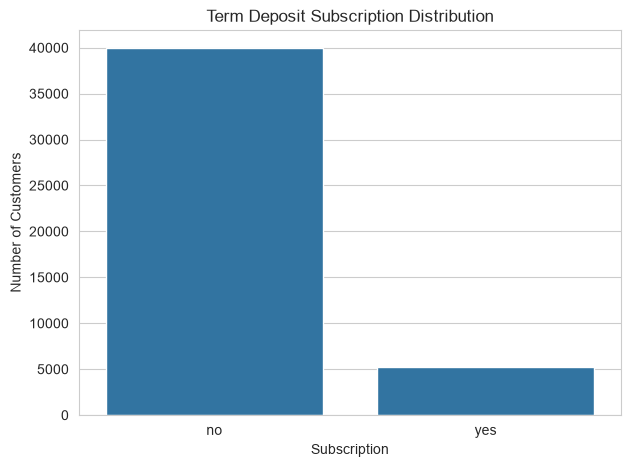


Target Distribution:


y
no     39922
yes     5289
Name: count, dtype: int64


Target Percentage:


y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64

In [ ]:
# Target Variable Distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="y"
)

plt.title("Term Deposit Subscription Distribution")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")

plt.show()

print("\nTarget Distribution:")
display(df["y"].value_counts())

print("\nTarget Percentage:")
display(df["y"].value_counts(normalize=True) * 100)

Univariate analysis – numerical features

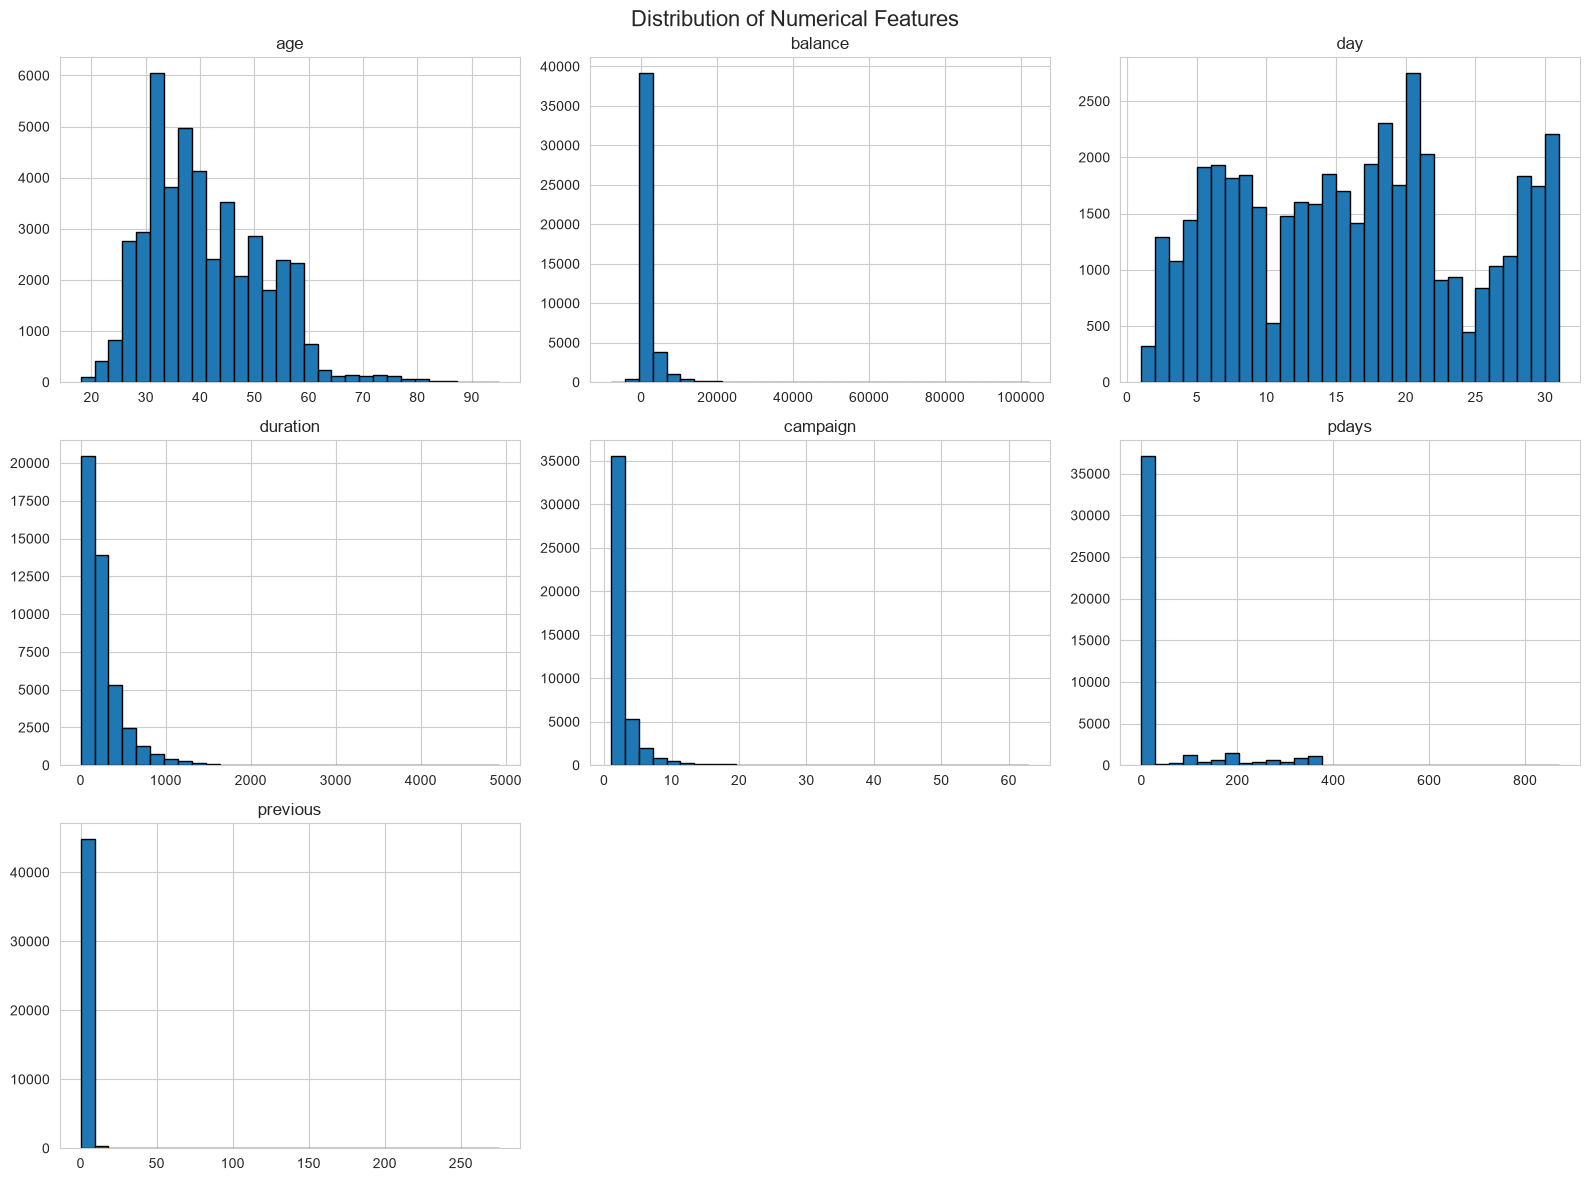

In [27]:
# Numerical Feature Distributions

numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

df[numerical_columns].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [28]:
# Check Skewness

skewness = df[numerical_columns].skew()

skewness_df = pd.DataFrame({
    "Feature": skewness.index,
    "Skewness": skewness.values
})

skewness_df["Distribution"] = np.where(
    skewness_df["Skewness"].abs() > 1,
    "Highly Skewed",
    "Approximately Symmetric"
)

display(
    skewness_df.sort_values(
        by="Skewness",
        ascending=False
    )
)

,Feature,Skewness,Distribution
6,previous,41.846454,Highly Skewed
1,balance,8.360308,Highly Skewed
4,campaign,4.898650,Highly Skewed
3,duration,3.144318,Highly Skewed
5,pdays,2.615715,Highly Skewed
0,age,0.684818,Approximately Symmetric
2,day,0.093079,Approximately Symmetric


Univariate analysis – categorical features

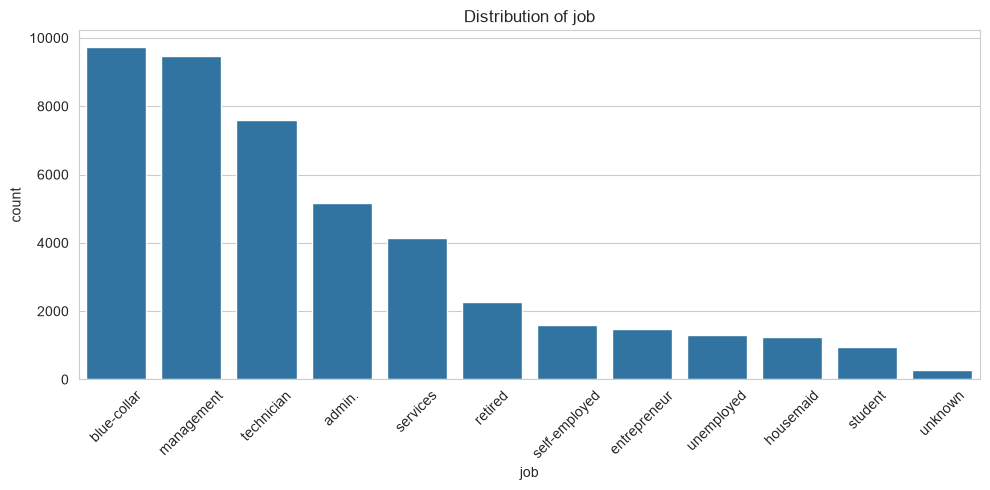

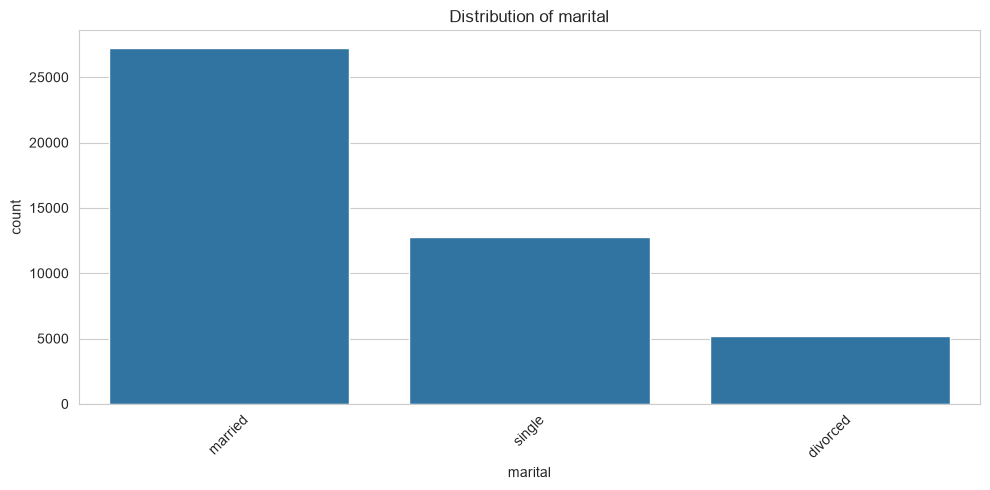

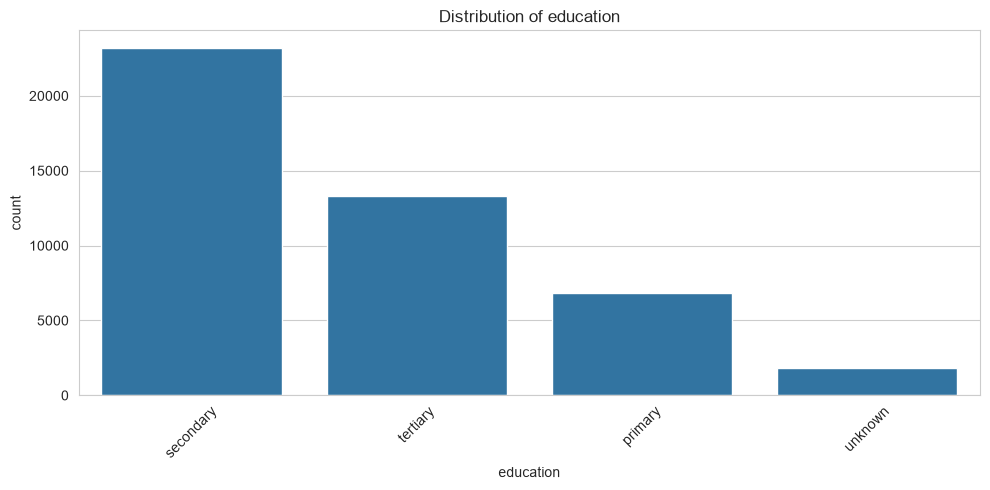

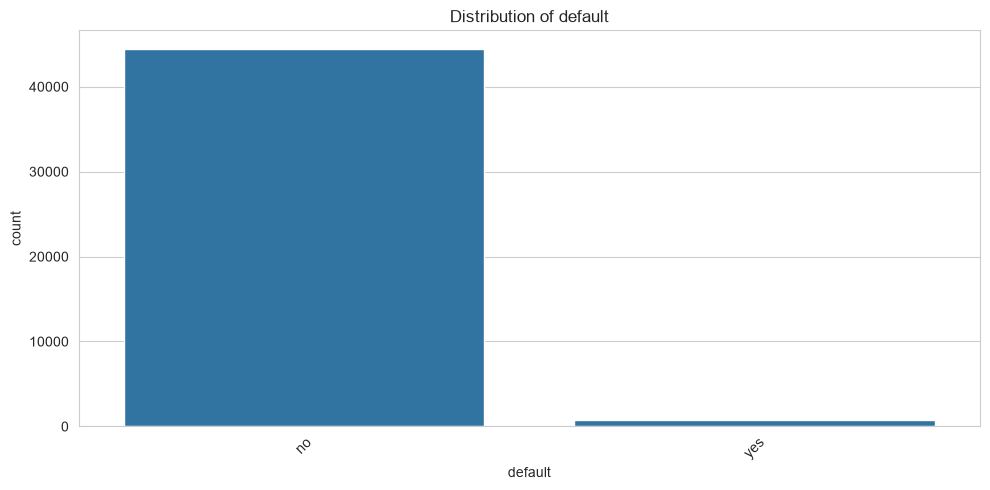

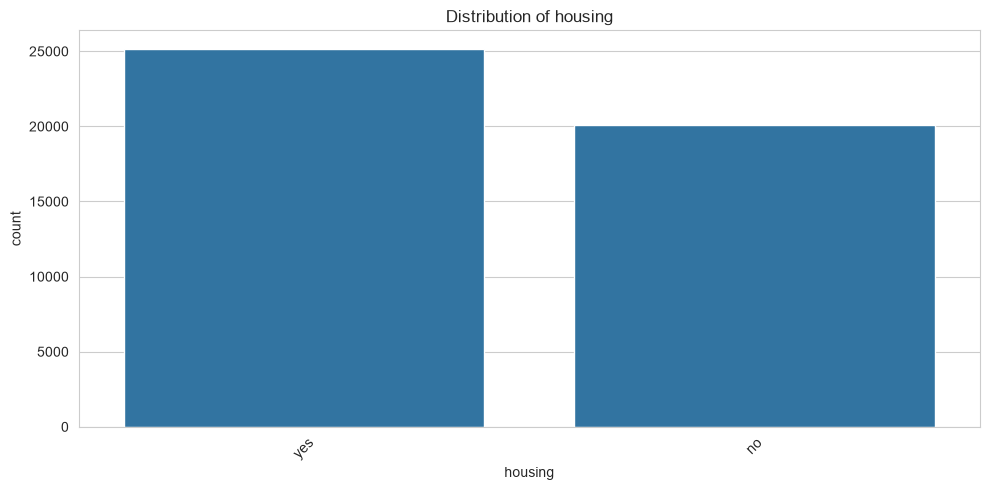

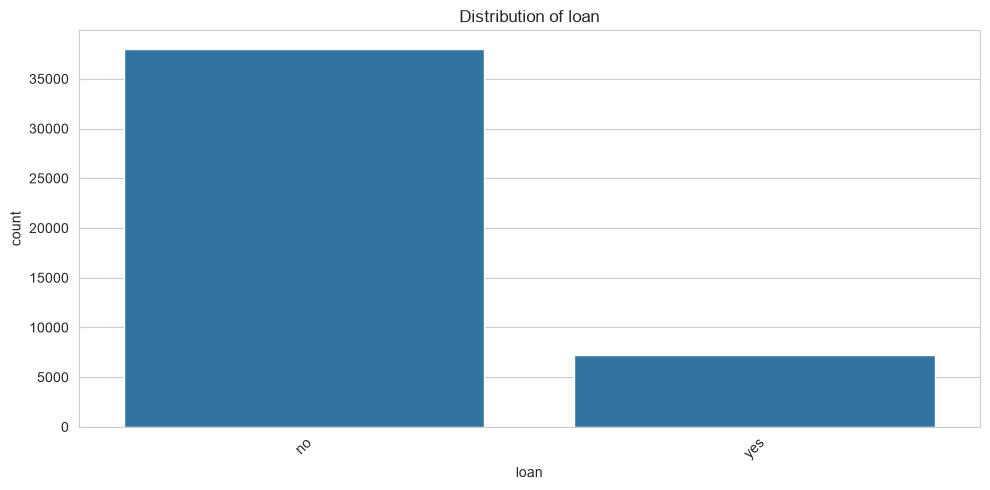

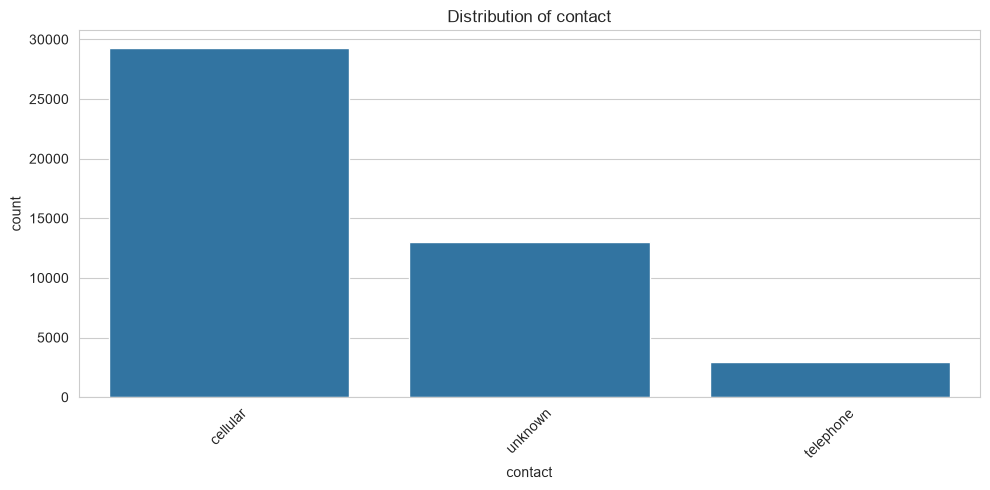

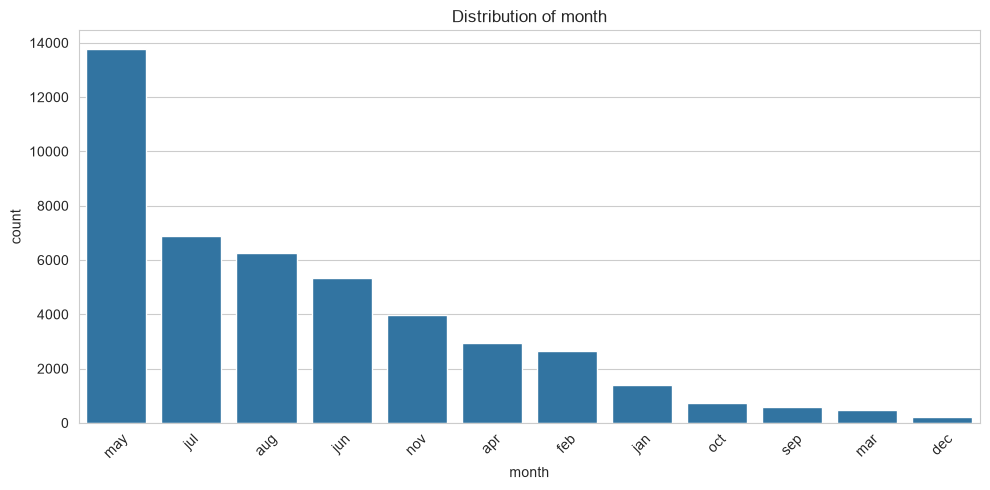

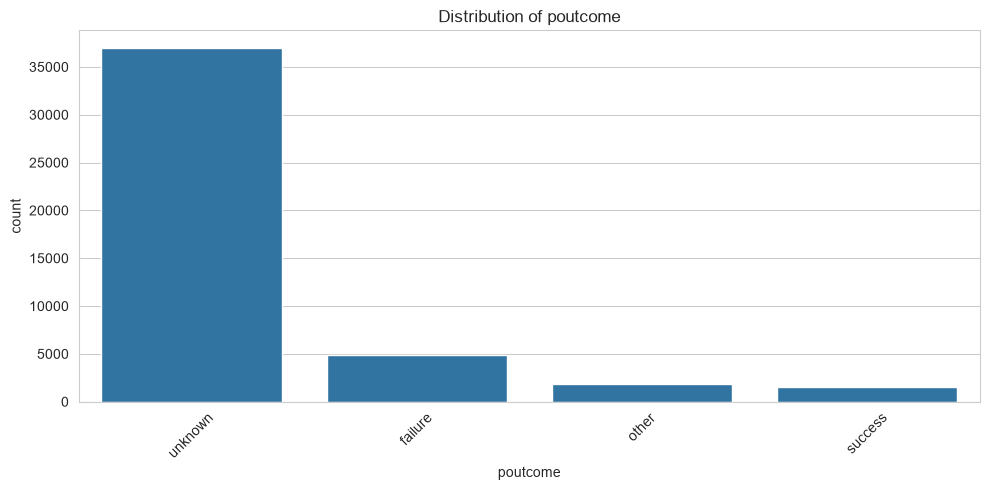

In [29]:
# Categorical Feature Distributions

categorical_columns = df.select_dtypes(
    include=["object", "str"]
).columns.drop("y")

for column in categorical_columns:

    plt.figure(figsize=(10, 5))

    order = df[column].value_counts().index

    sns.countplot(
        data=df,
        x=column,
        order=order
    )

    plt.title(f"Distribution of {column}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Bivariate analysis – numerical features vs target

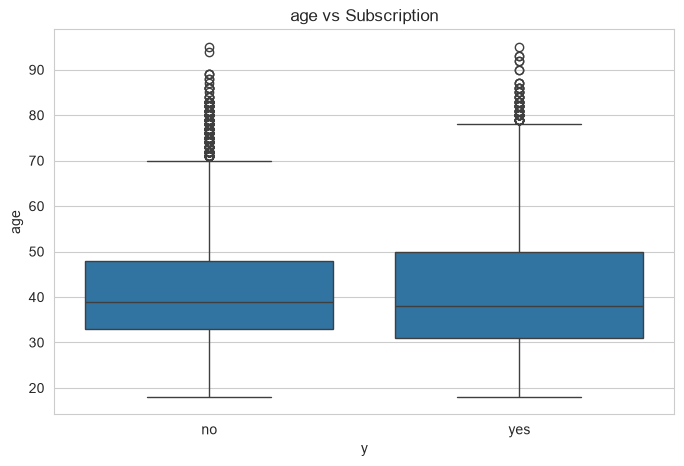

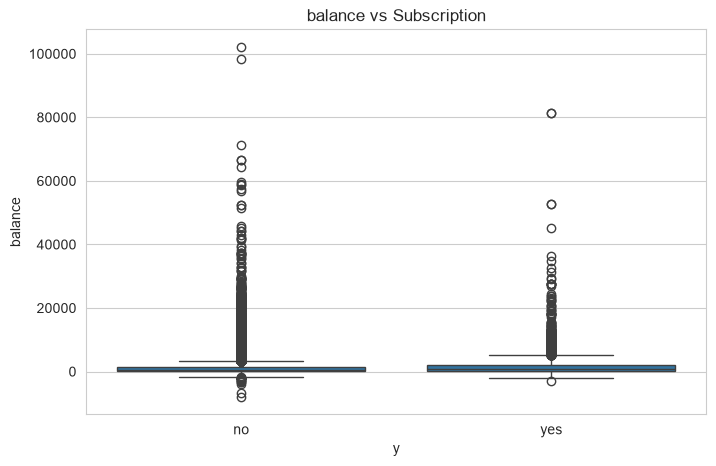

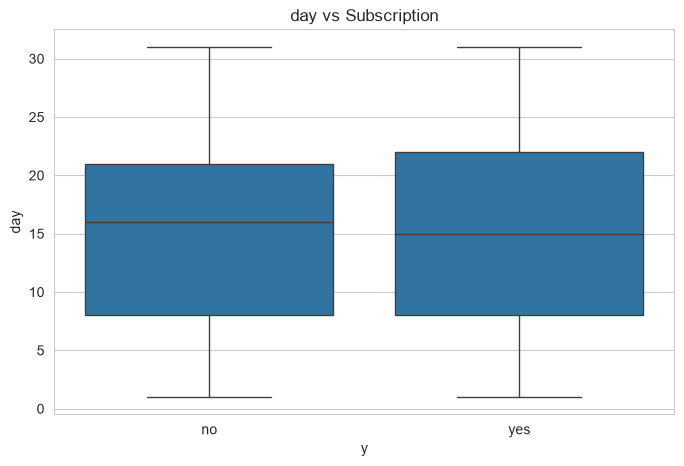

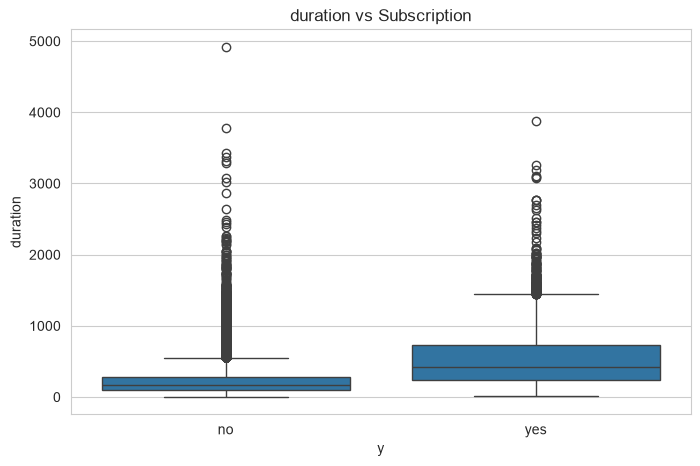

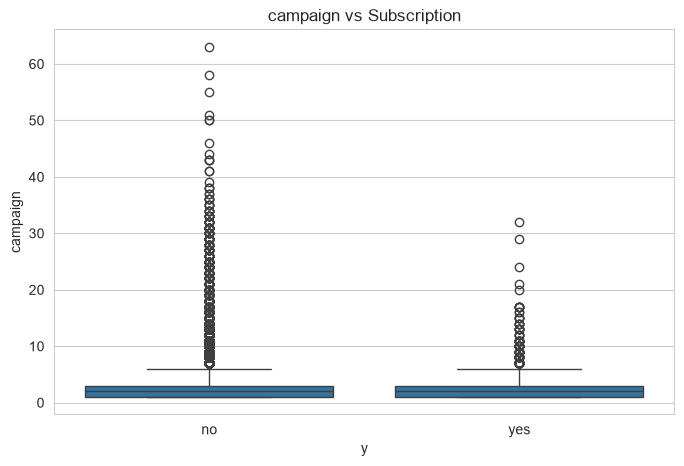

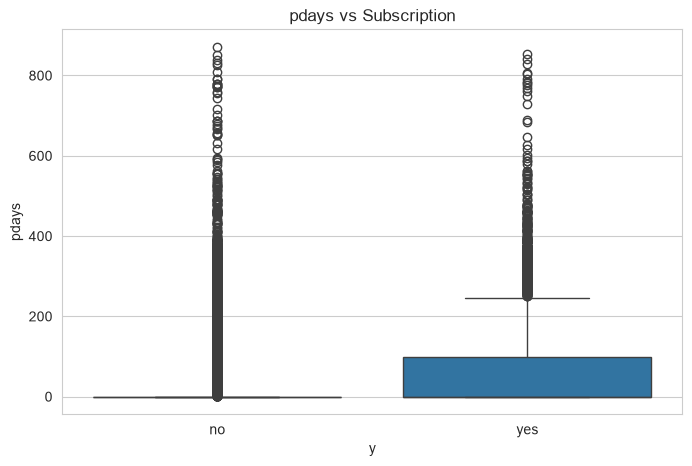

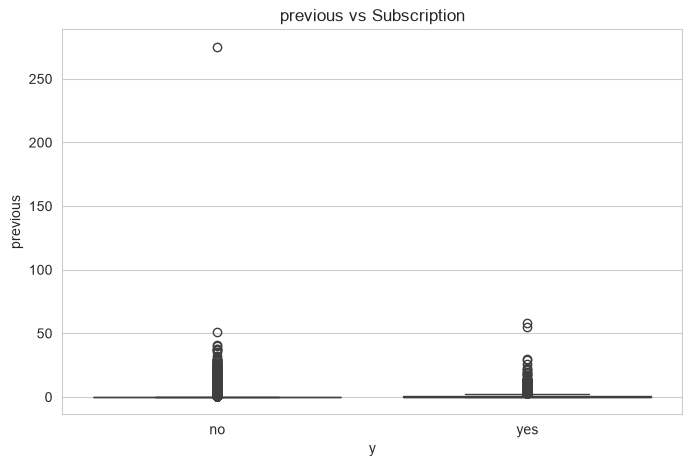

In [30]:
# Numerical Features vs Target

for column in numerical_columns:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="y",
        y=column
    )

    plt.title(f"{column} vs Subscription")
    plt.show()

Bivariate analysis – categorical features vs target

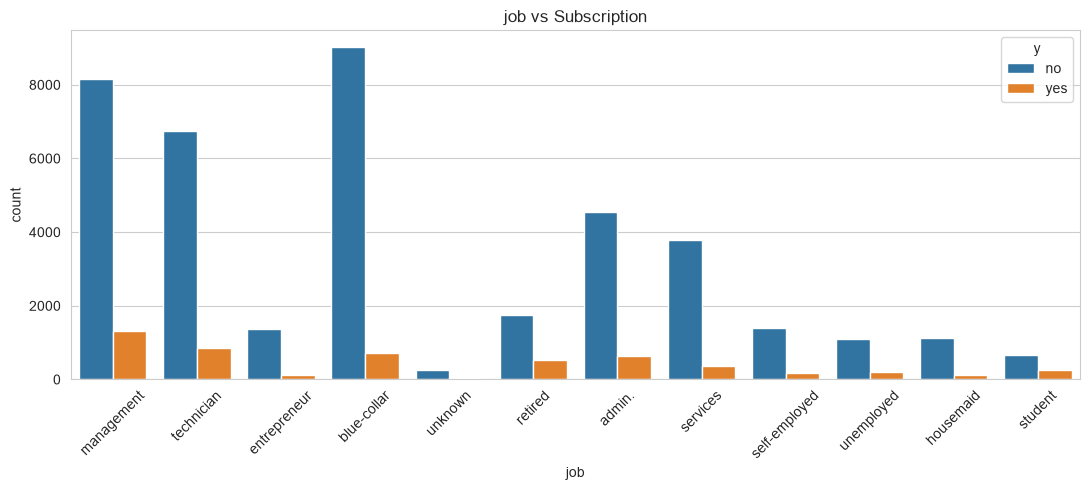

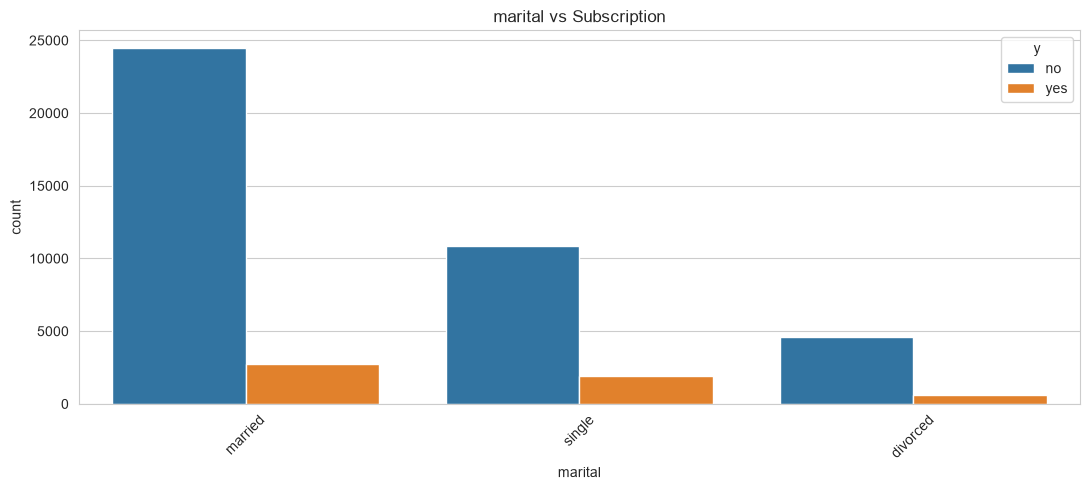

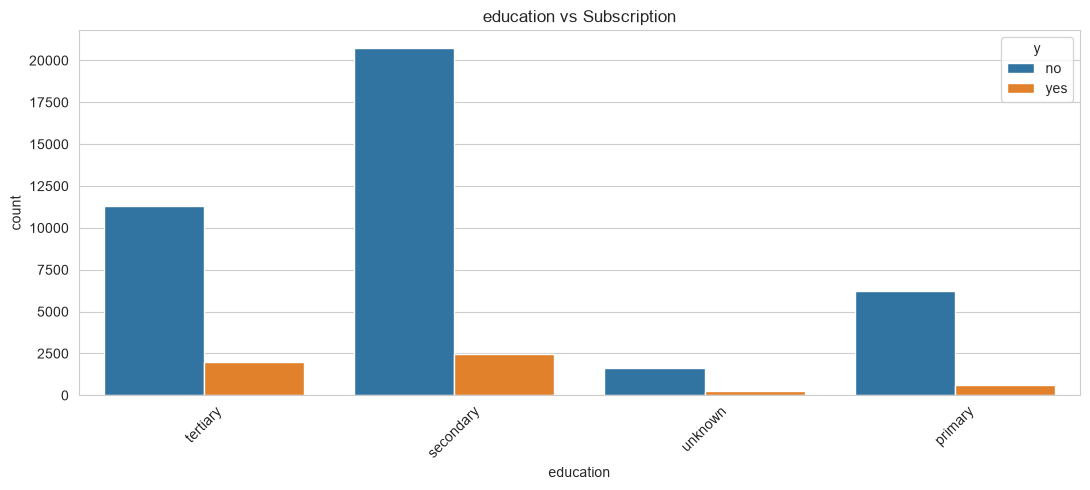

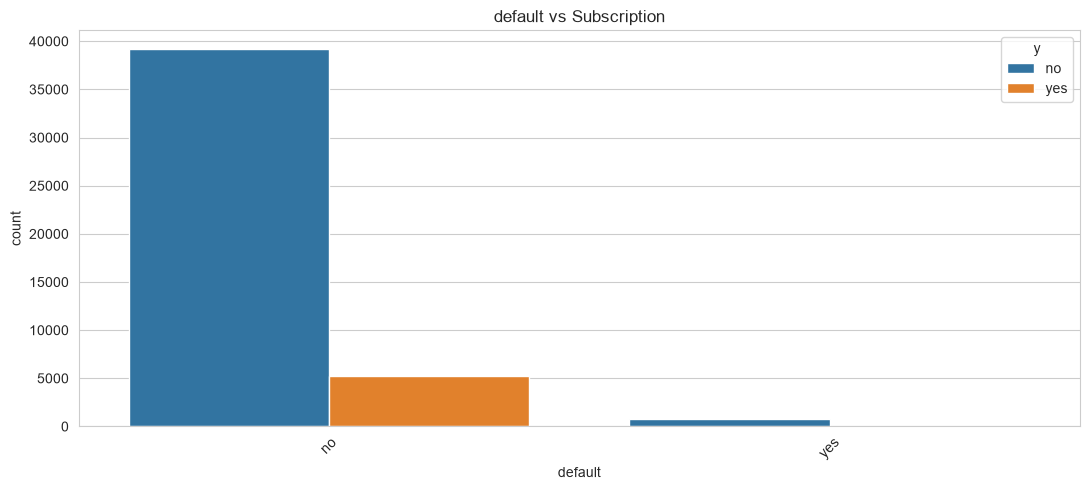

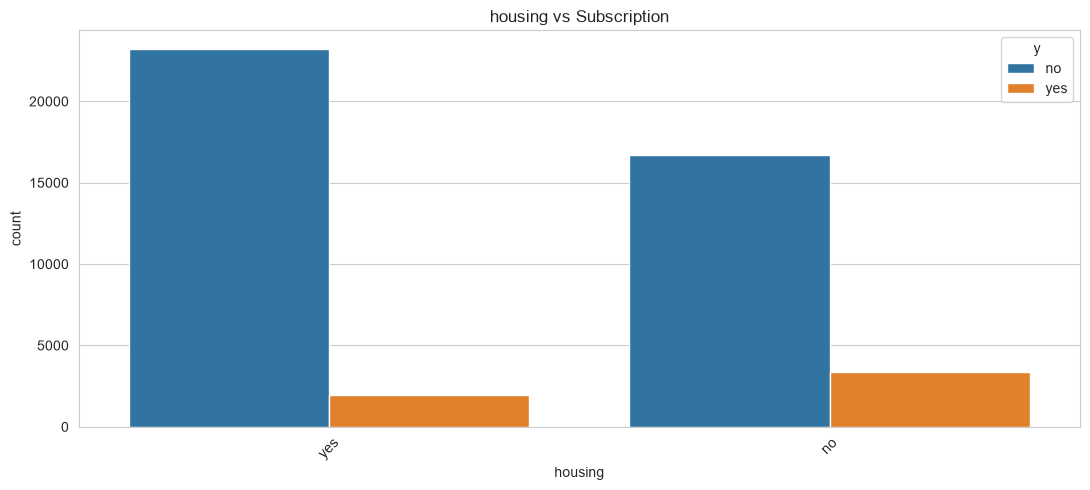

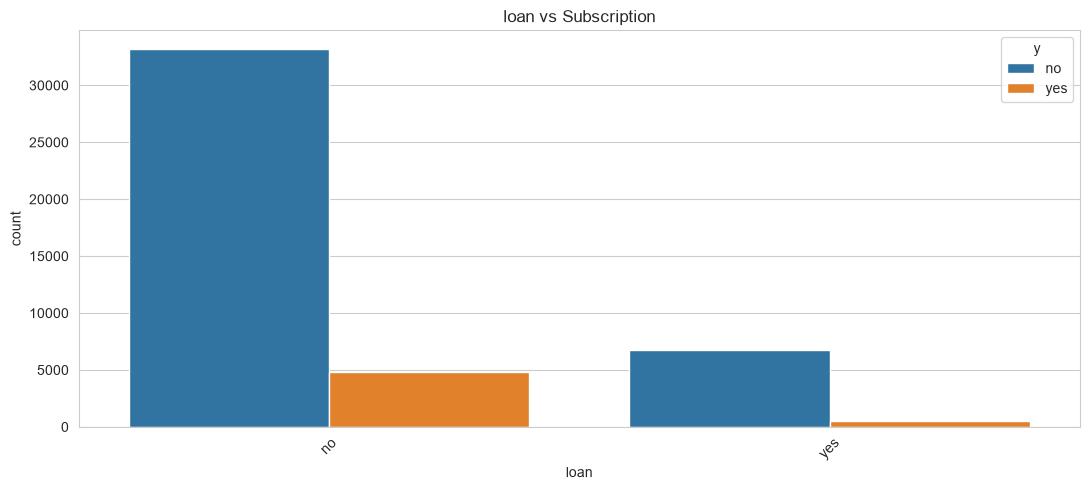

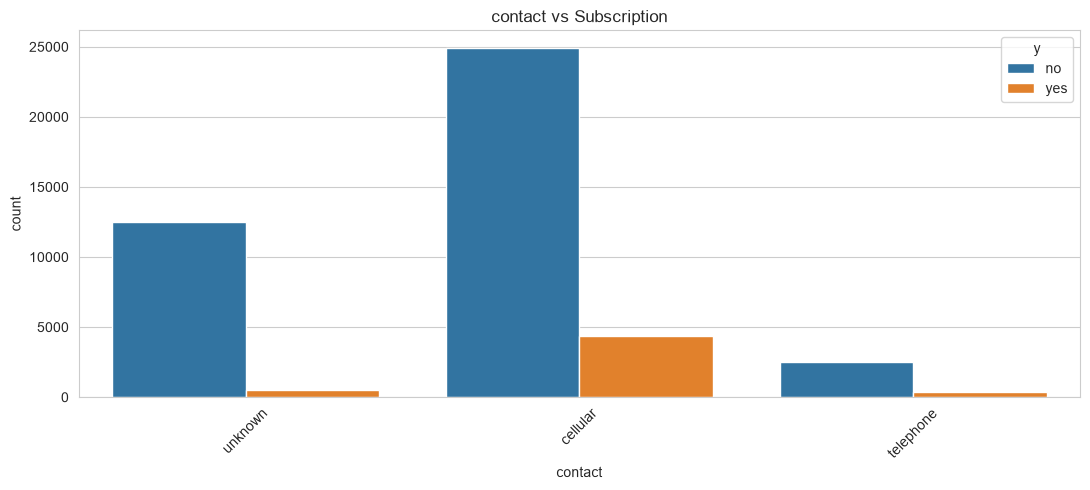

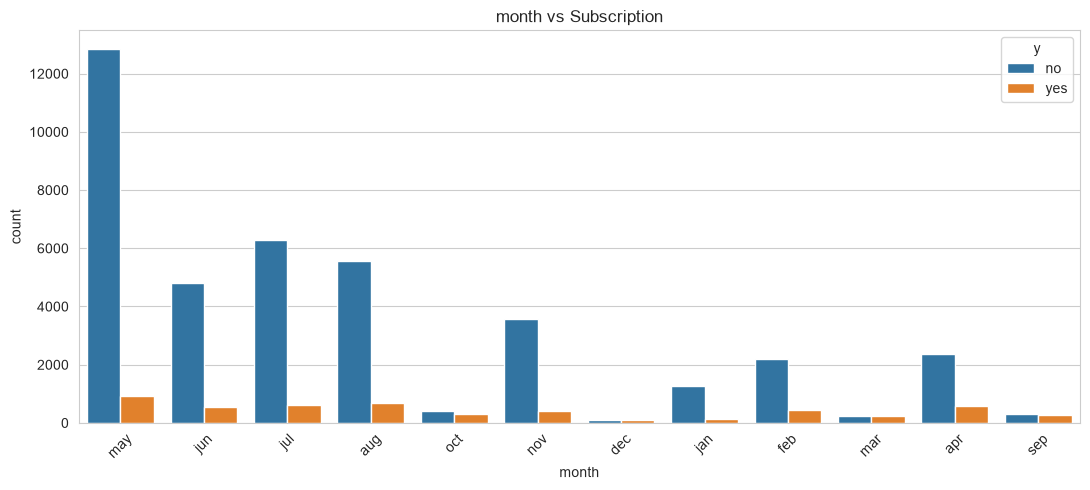

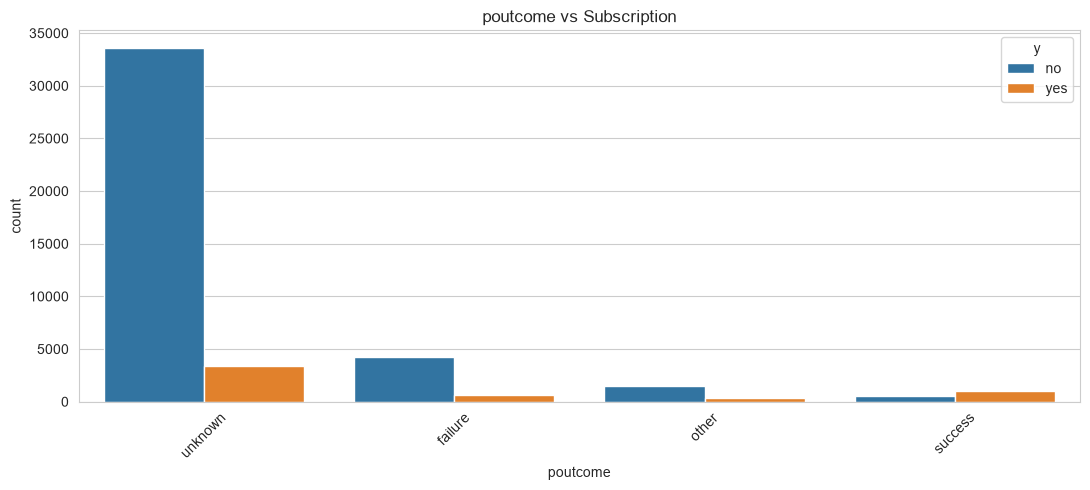

In [31]:
# Categorical Features vs Target

for column in categorical_columns:

    plt.figure(figsize=(11, 5))

    sns.countplot(
        data=df,
        x=column,
        hue="y"
    )

    plt.title(f"{column} vs Subscription")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Subscription rate by categorical features

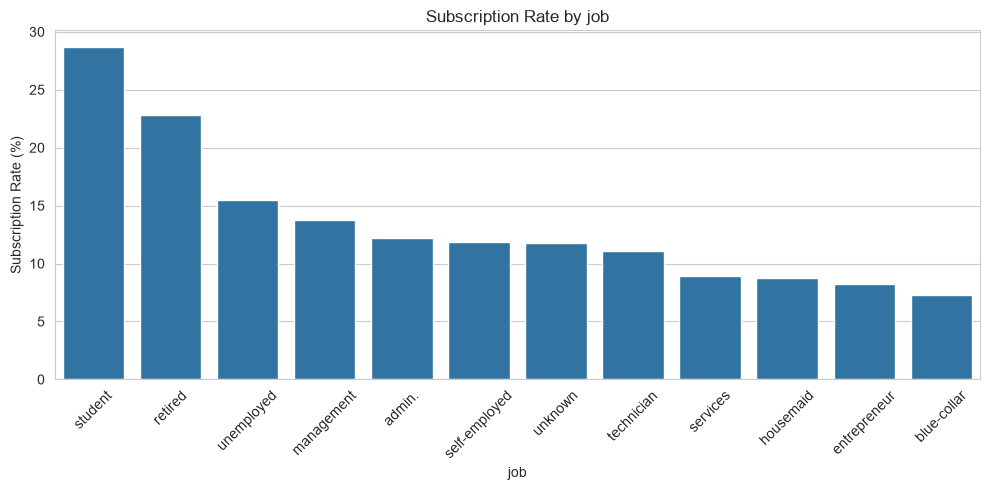

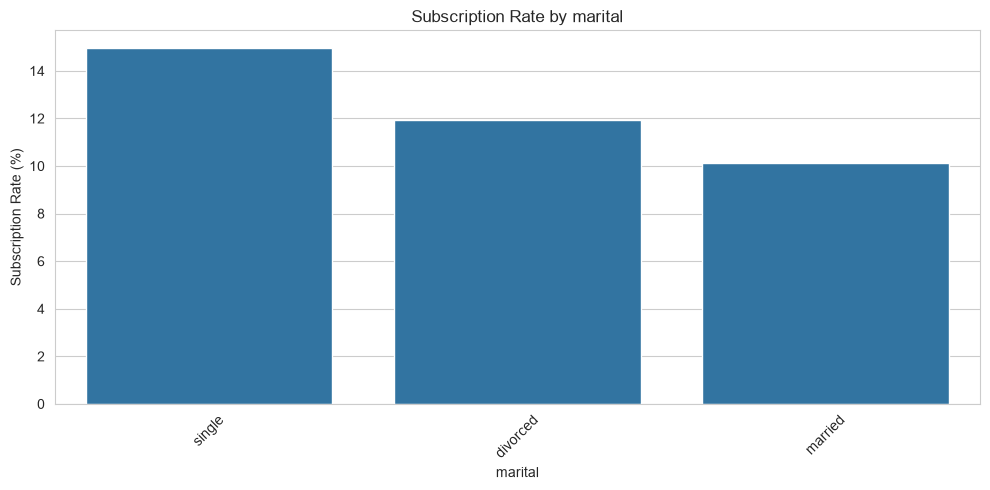

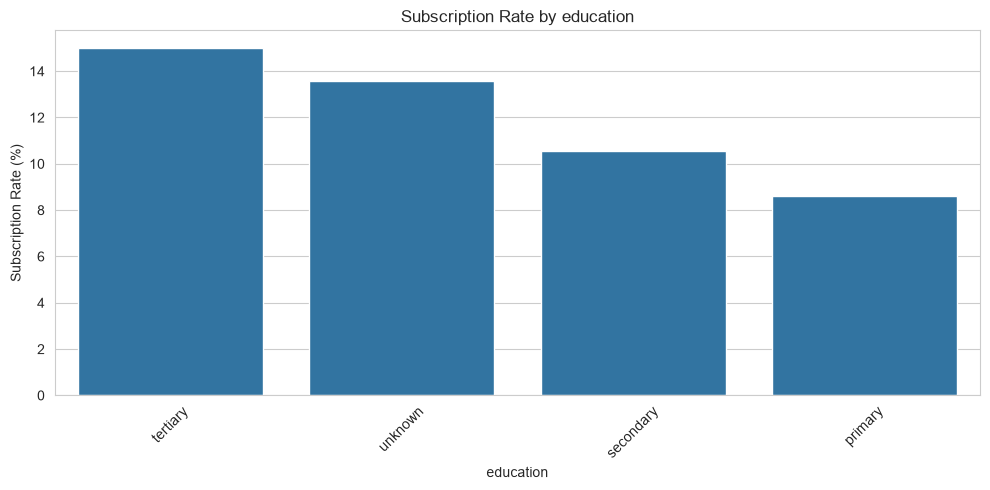

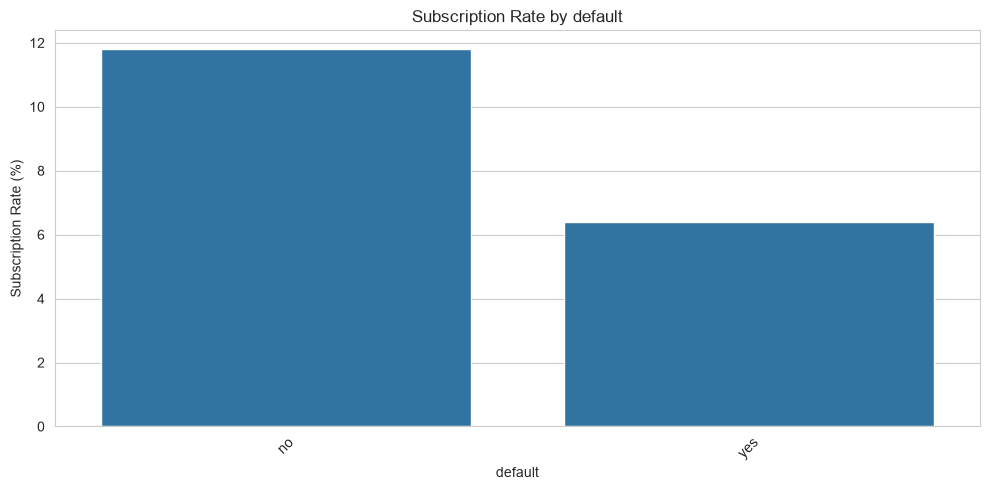

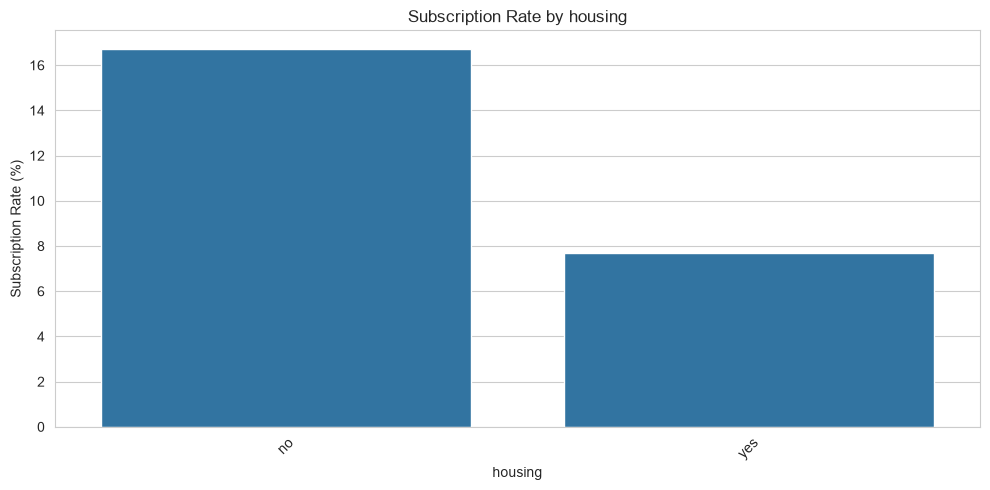

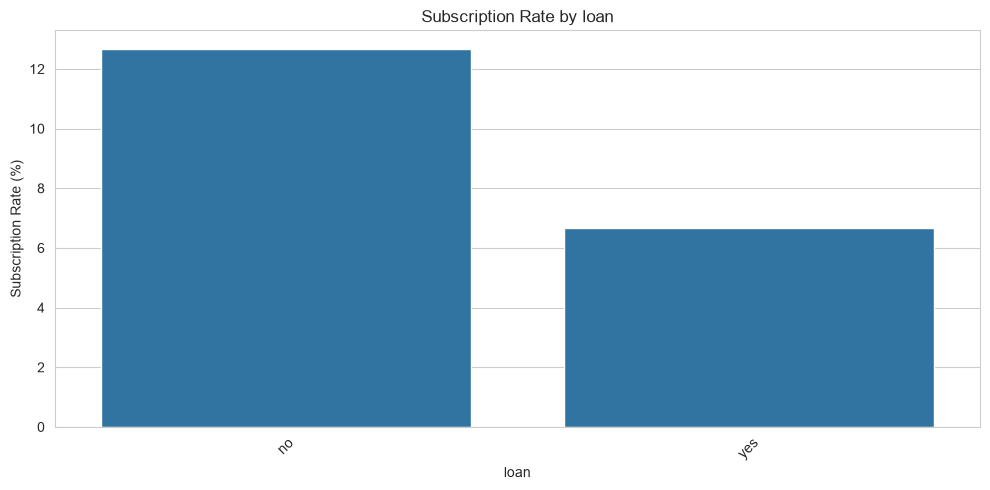

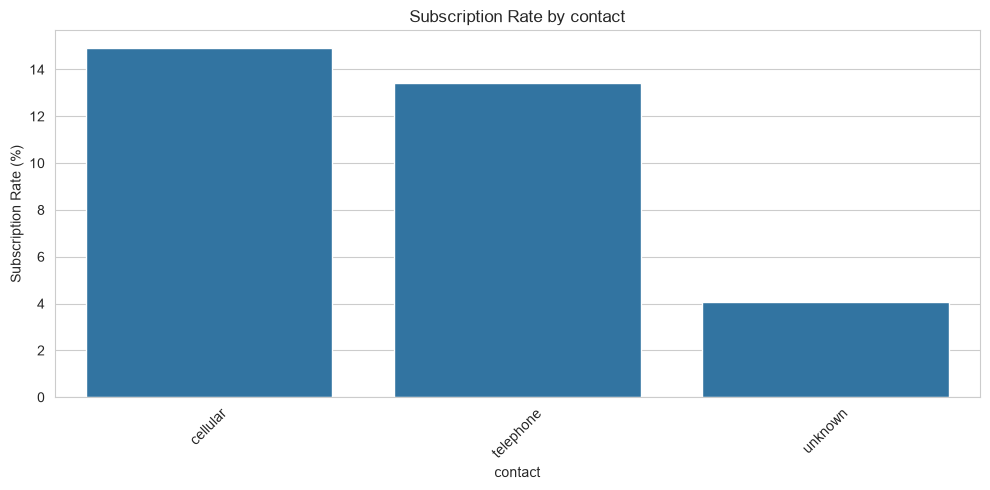

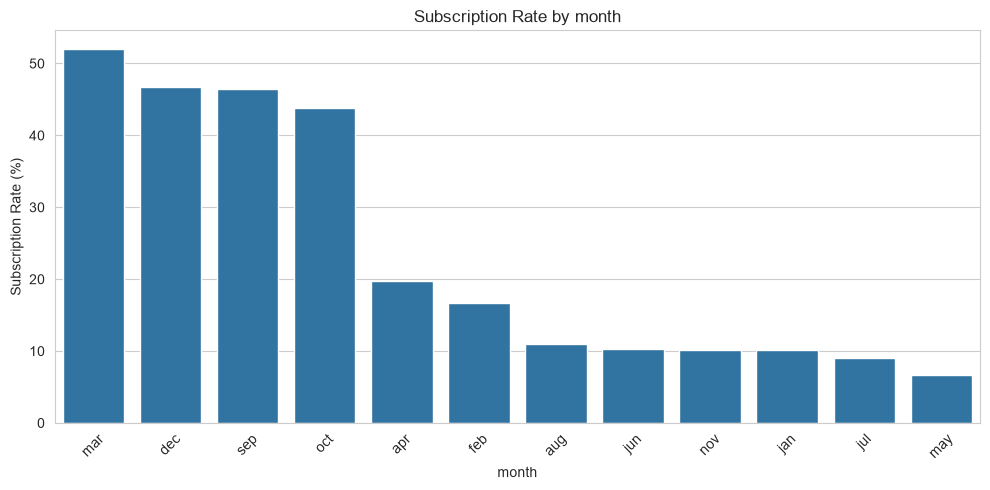

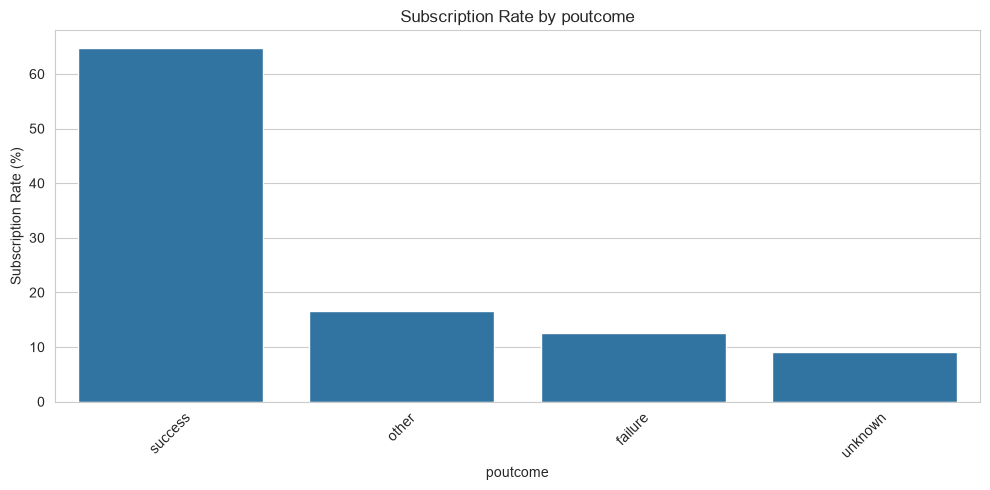

In [32]:
# Subscription Rate by Categorical Features

for column in categorical_columns:

    subscription_rate = (
        df.groupby(column, observed=False)["y"]
        .apply(lambda x: (x == "yes").mean() * 100)
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(10, 5))

    sns.barplot(
        x=subscription_rate.index,
        y=subscription_rate.values
    )

    plt.title(f"Subscription Rate by {column}")
    plt.xlabel(column)
    plt.ylabel("Subscription Rate (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

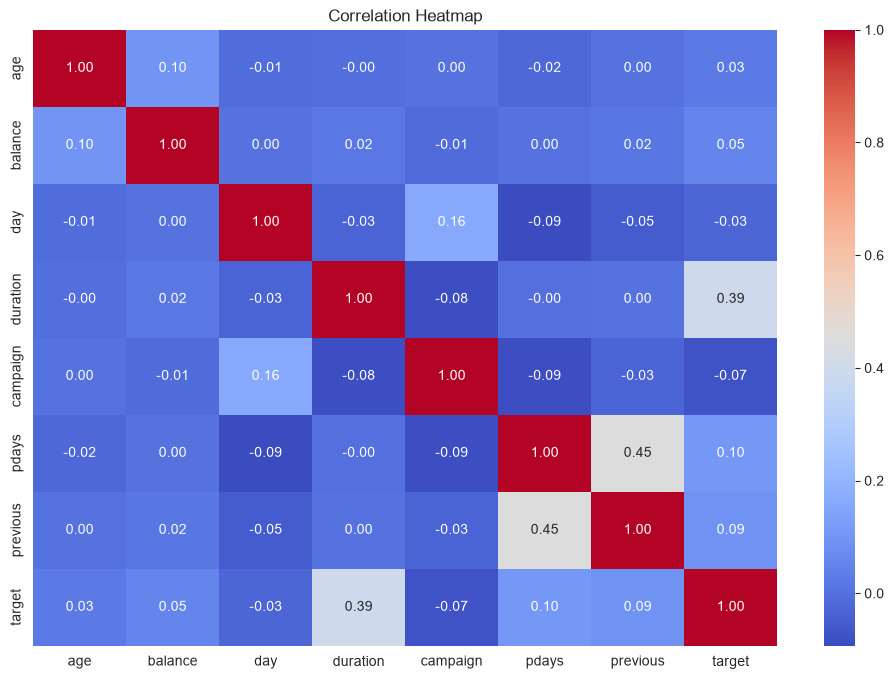

In [33]:
# Correlation Heatmap

correlation_df = df[numerical_columns].copy()

correlation_df["target"] = df["y"].map({
    "no": 0,
    "yes": 1
})

correlation_matrix = correlation_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

Multivariate analysis – pairplot

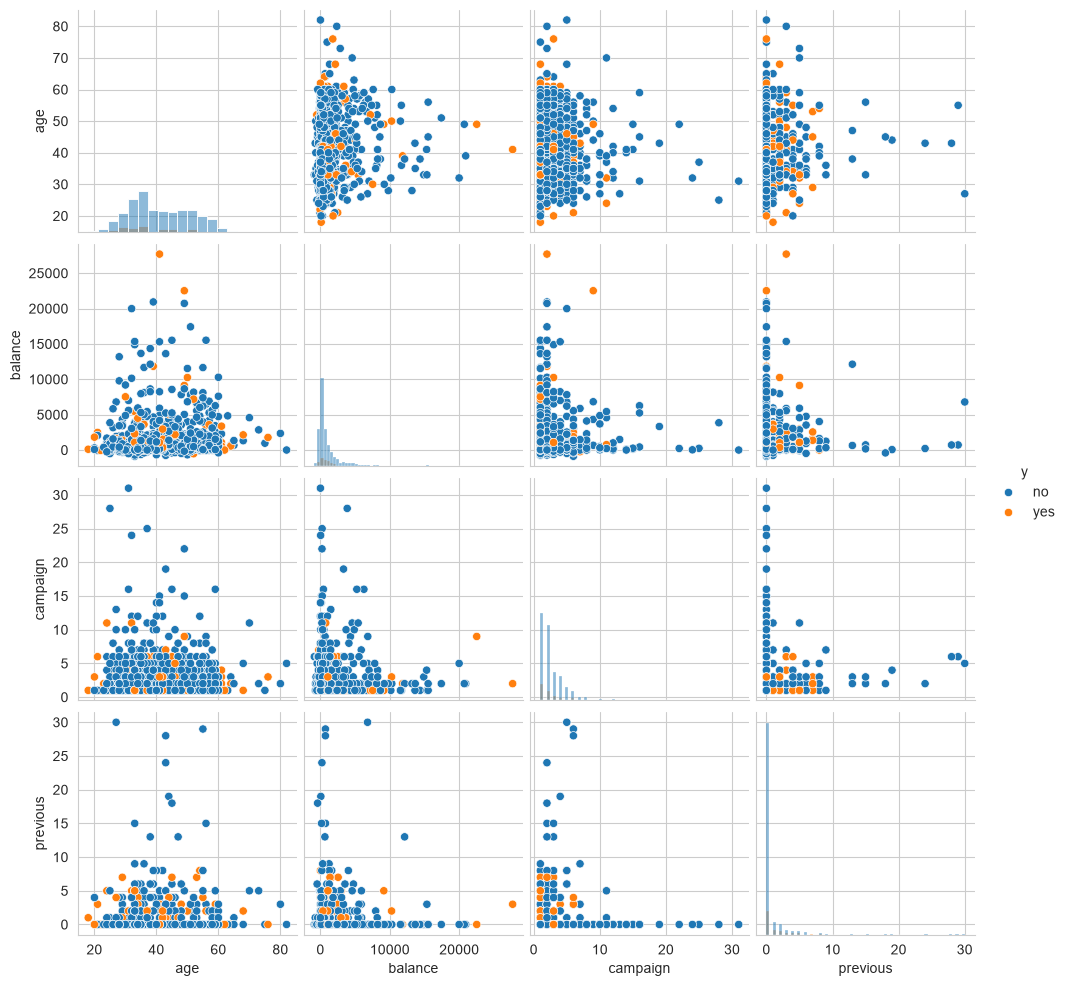

In [34]:
# Pairplot

pairplot_columns = [
    "age",
    "balance",
    "campaign",
    "previous",
    "y"
]

sample_df = df[pairplot_columns].sample(
    n=min(1000, len(df)),
    random_state=42
)

sns.pairplot(
    sample_df,
    hue="y",
    diag_kind="hist"
)

plt.show()

**Outlier detection and treatment**

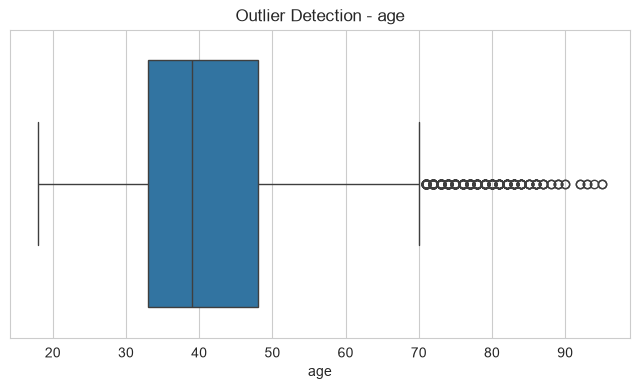

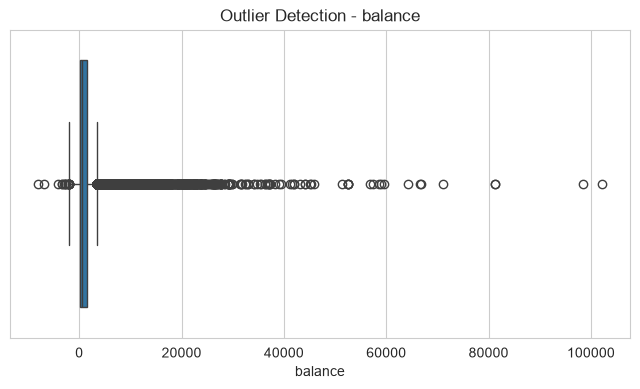

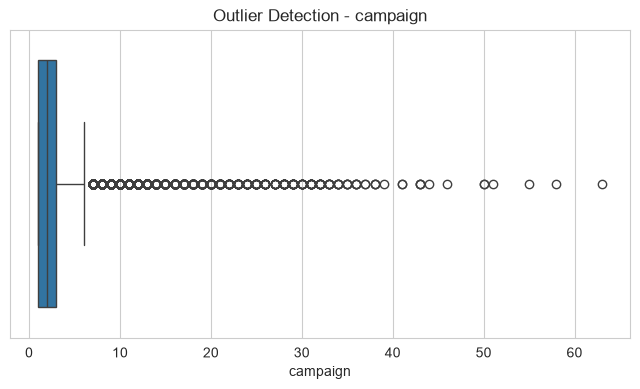

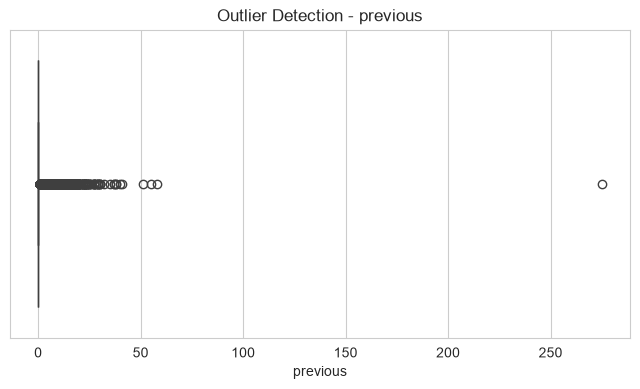

In [35]:
#Outlier Detection

outlier_columns = [
    "age",
    "balance",
    "campaign",
    "previous"
]

for column in outlier_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        x=df[column]
    )

    plt.title(f"Outlier Detection - {column}")
    plt.show()

In [36]:
# IQR Outlier Analysis

outlier_summary = []

for column in outlier_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ).sum()

    outlier_summary.append({
        "Feature": column,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": outlier_count,
        "Outlier Percentage": (
            outlier_count / len(df)
        ) * 100
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df)

,Feature,Lower Limit,Upper Limit,Outlier Count,Outlier Percentage
0,age,10.5,70.5,487,1.077171
1,balance,-1962.0,3462.0,4729,10.459844
2,campaign,-2.0,6.0,3064,6.777112
3,previous,0.0,0.0,8257,18.263255


Train-test split before outlier treatment

In [37]:
# Step 7: Prepare Features and Target

# Remove duration to avoid target leakage
X = df.drop(columns=["y", "duration"])

# Convert target to binary values
y = df["y"].map({
    "no": 0,
    "yes": 1
})

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Feature Shape: (45211, 15)
Target Shape: (45211,)

Features:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']


In [38]:
# Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (36168, 15)
Testing Features: (9043, 15)
Training Target: (36168,)
Testing Target: (9043,)


In [39]:
# IQR-Based Outlier Treatment
# Fit boundaries only on training data

cap_columns = [
    "age",
    "balance",
    "campaign",
    "previous"
]

outlier_bounds = {}

for column in cap_columns:

    Q1 = X_train[column].quantile(0.25)
    Q3 = X_train[column].quantile(0.75)

    IQR = Q3 - Q1

    upper_limit = Q3 + (1.5 * IQR)

    outlier_bounds[column] = upper_limit

    X_train[column] = X_train[column].clip(
        upper=upper_limit
    )

    X_test[column] = X_test[column].clip(
        upper=upper_limit
    )

print("Outlier treatment completed!")

print("\nUpper Capping Limits:")
print(outlier_bounds)

Outlier treatment completed!

Upper Capping Limits:
{'age': np.float64(70.5), 'balance': np.float64(3464.625), 'campaign': np.float64(6.0), 'previous': np.float64(0.0)}


Feature engineering and encoding

In [40]:
# Step 8: Feature Engineering

X_train["previously_contacted"] = (
    X_train["pdays"] != -1
).astype(int)

X_test["previously_contacted"] = (
    X_test["pdays"] != -1
).astype(int)

print("New feature created successfully!")

display(X_train.head())

New feature created successfully!


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,previously_contacted
24001,36.0,technician,divorced,secondary,no,861.000,no,no,telephone,29,aug,2,-1,0,unknown,0
43409,24.0,student,single,secondary,no,3464.625,no,no,cellular,5,apr,4,185,0,failure,1
20669,44.0,technician,single,secondary,no,244.000,yes,no,cellular,12,aug,4,-1,0,unknown,0
18810,48.0,unemployed,married,secondary,no,0.000,no,no,telephone,31,jul,6,-1,0,unknown,0
23130,38.0,technician,married,secondary,no,257.000,no,no,cellular,26,aug,6,-1,0,unknown,0


In [41]:
# Identify Numerical and Categorical Features

numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTotal Numerical Features:", len(numerical_features))
print("Total Categorical Features:", len(categorical_features))

Numerical Features:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'previously_contacted']

Categorical Features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Total Numerical Features: 7
Total Categorical Features: 9


Build the preprocessing pipeline

In [42]:
# Create Numerical Preprocessing Pipeline

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Create Categorical Preprocessing Pipeline

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

print("Numerical and categorical pipelines created!")

Numerical and categorical pipelines created!


In [43]:
# Combine Both Pipelines

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

print("Column Transformer Created Successfully!")

Column Transformer Created Successfully!


In [44]:
# Fit Preprocessor on Training Data Only

X_train_processed = preprocessor.fit_transform(
    X_train
)

print("Training data preprocessing completed!")
print("Processed Training Shape:", X_train_processed.shape)

Training data preprocessing completed!
Processed Training Shape: (36168, 51)


In [ ]:
# Transform Testing Data

X_test_processed = preprocessor.transform(
    X_test
)

print("Testing data preprocessing completed!")
print("Processed Testing Shape:", X_test_processed.shape)

Testing data preprocessing completed!
Processed Testing Shape: (9043, 51)


In [46]:
# Convert Processed Arrays into DataFrames

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Processed DataFrames Created!")

print("\nTraining Data:")
display(X_train_processed.head())

print("\nTesting Data:")
display(X_test_processed.head())

Processed DataFrames Created!

Training Data:


,age,balance,day,campaign,pdays,previous,previously_contacted,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown,marital_divorced,marital_married,marital_single,education_primary,education_secondary,education_tertiary,education_unknown,default_no,default_yes,housing_no,housing_yes,loan_no,loan_yes,contact_cellular,contact_telephone,contact_unknown,month_apr,month_aug,month_dec,month_feb,month_jan,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
24001,-0.463826,-0.062807,1.582124,-0.245119,-0.410910,0.0,-0.471755,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
43409,-1.617412,2.146006,-1.298384,1.004857,1.446096,0.0,2.119745,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
20669,0.305232,-0.586246,-0.458236,1.004857,-0.410910,0.0,-0.471755,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
18810,0.689761,-0.793246,1.822166,2.254833,-0.410910,0.0,-0.471755,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
23130,-0.271561,-0.575217,1.222060,2.254833,-0.410910,0.0,-0.471755,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0



Testing Data:


,age,balance,day,campaign,pdays,previous,previously_contacted,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown,marital_divorced,marital_married,marital_single,education_primary,education_secondary,education_tertiary,education_unknown,default_no,default_yes,housing_no,housing_yes,loan_no,loan_yes,contact_cellular,contact_telephone,contact_unknown,month_apr,month_aug,month_dec,month_feb,month_jan,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
1392,-0.079297,-0.250295,-0.938321,-0.245119,-0.41091,0.0,-0.471755,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
7518,0.305232,-0.472565,1.702145,-0.245119,-0.41091,0.0,-0.471755,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
12007,-0.944487,-0.491229,0.501933,1.629845,-0.41091,0.0,-0.471755,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
5536,-0.463826,-0.237570,0.861997,1.004857,-0.41091,0.0,-0.471755,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
29816,-0.656090,0.836455,-1.418405,-0.870107,-0.41091,0.0,-0.471755,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [47]:
# Verify Feature Scaling

display(
    X_train_processed[numerical_features].describe().T
)

,count,mean,std,min,25%,50%,75%,max
age,36168.0,1.650232e-16,1.000014,-2.194205,-0.752222,-0.175429,0.689761,2.852735
balance,36168.0,-5.657938e-17,1.000014,-7.596251,-0.730467,-0.410635,0.420122,2.146006
day,36168.0,8.801237e-17,1.000014,-1.778469,-0.938321,0.021849,0.621954,1.822166
campaign,36168.0,-7.897539e-17,1.000014,-0.870107,-0.870107,-0.245119,0.379869,2.254833
pdays,36168.0,2.514639e-17,1.000014,-0.410910,-0.410910,-0.410910,-0.410910,8.295054
previous,36168.0,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
previously_contacted,36168.0,-2.612867e-17,1.000014,-0.471755,-0.471755,-0.471755,-0.471755,2.119745


In [49]:
# Define Project Root

PROJECT_ROOT = data_path.resolve().parents[2]

print("Project Root:", PROJECT_ROOT)

Project Root: E:\Innomatics\ML_Innomatics\BANK_MARKET_CAMPAIGN_PREDICTION


In [50]:
# Save Cleaned Dataset

processed_dir = PROJECT_ROOT / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(
    processed_dir / "bank_marketing_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [51]:
# Save Processed Training Data

train_final = X_train_processed.copy()
train_final["y"] = y_train

train_final.to_csv(
    processed_dir / "train_processed.csv",
    index=False
)

print("Processed Training Dataset Saved!")
print("Shape:", train_final.shape)

Processed Training Dataset Saved!
Shape: (36168, 52)


In [52]:
# Save Processed Testing Data

test_final = X_test_processed.copy()
test_final["y"] = y_test

test_final.to_csv(
    processed_dir / "test_processed.csv",
    index=False
)

print("Processed Testing Dataset Saved!")
print("Shape:", test_final.shape)

Processed Testing Dataset Saved!
Shape: (9043, 52)


In [53]:
# Save Fitted Preprocessor

models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    preprocessor,
    models_dir / "preprocessor_sprint1.joblib"
)

print("Preprocessor saved successfully!")

Preprocessor saved successfully!


In [41]:
# Standardize only the original numerical features; encoded categorical indicators remain 0/1.

# Apply Standardization

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_processed = X_encoded.copy()

X_processed[numerical_columns] = scaler.fit_transform(
    X_processed[numerical_columns]
)

print("Feature scaling completed successfully.")

Feature scaling completed successfully.


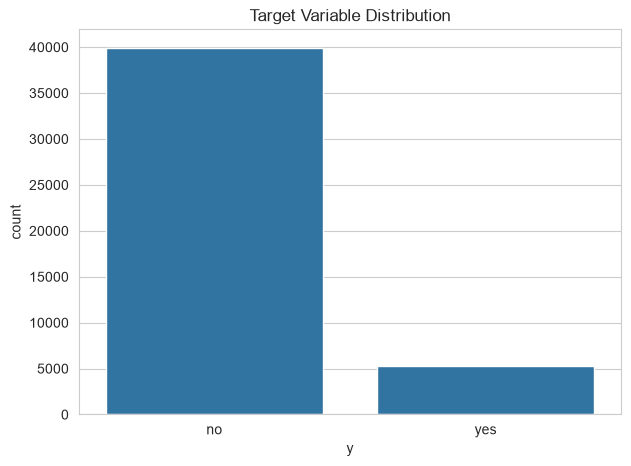

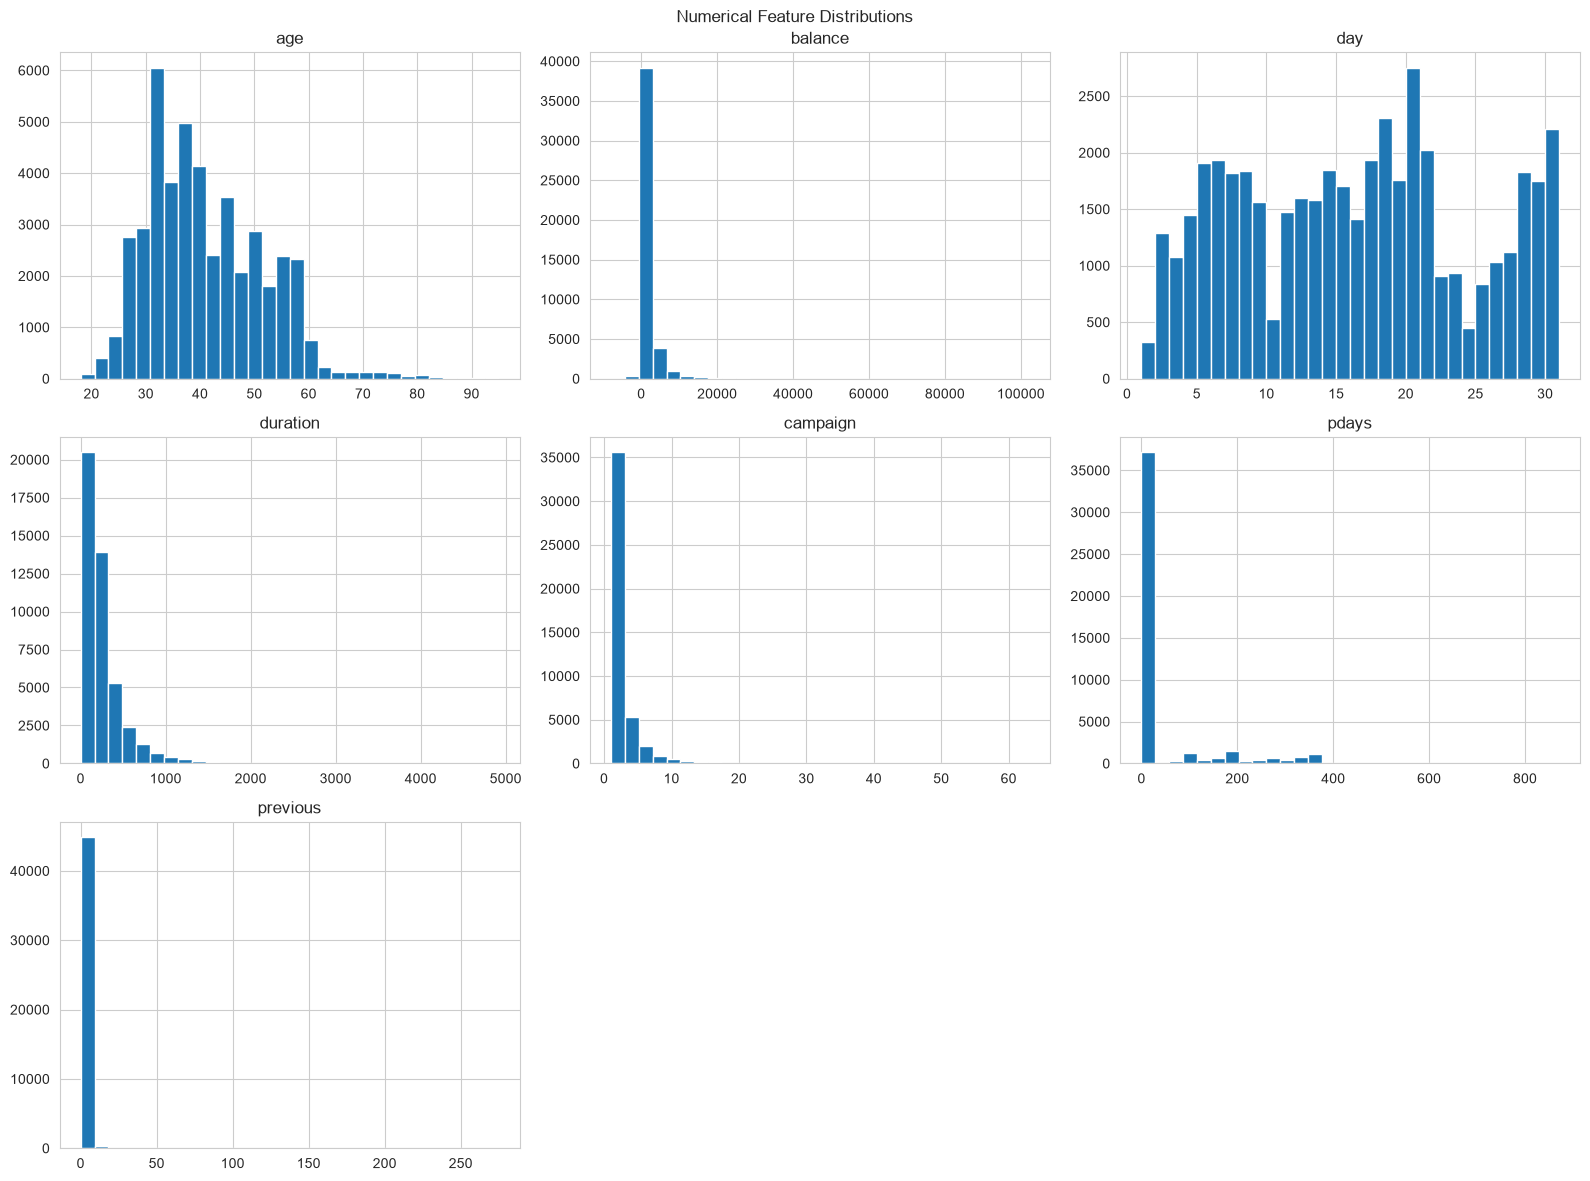

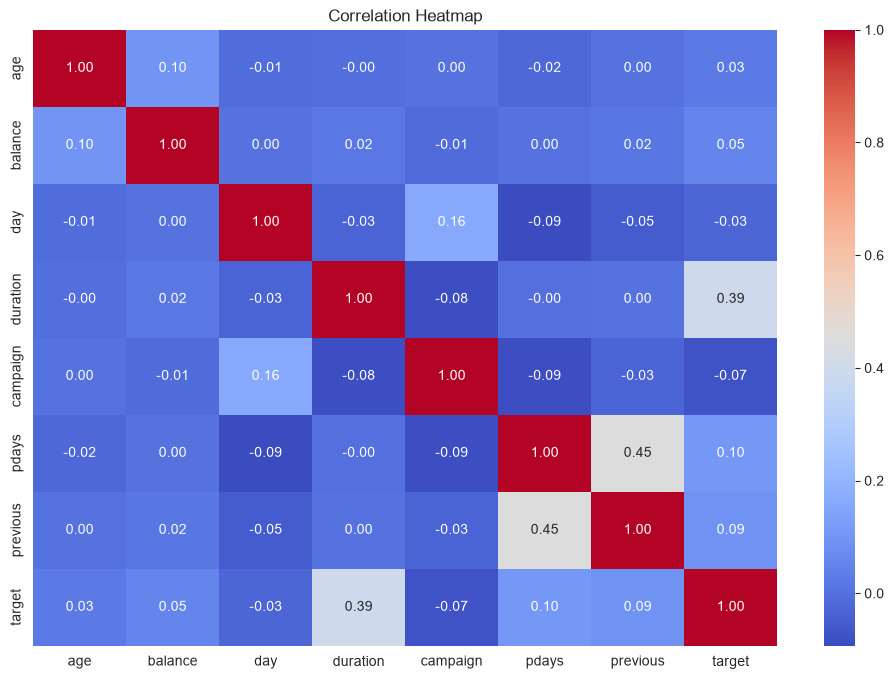

EDA visualizations saved successfully!


In [54]:
# Save EDA Visualizations

figures_dir = PROJECT_ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# 1. Target Distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="y")

plt.title("Target Variable Distribution")
plt.savefig(
    figures_dir / "target_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 2. Numerical Distributions
df[numerical_columns].hist(
    figsize=(16, 12),
    bins=30
)

plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()

plt.savefig(
    figures_dir / "numerical_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 3. Correlation Heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.savefig(
    figures_dir / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("EDA visualizations saved successfully!")

In [55]:
# Sprint 1 Final Validation

print("=" * 55)
print("SPRINT 1: DATA UNDERSTANDING & PREPROCESSING")
print("=" * 55)

print("\nOriginal Dataset Shape:", df.shape)

print("\nCleaned Dataset Shape:", df.shape)

print("\nTraining Dataset Shape:", X_train_processed.shape)
print("Testing Dataset Shape:", X_test_processed.shape)

print("\nTarget Distribution:")
print(y.value_counts())

print("\nMissing Values in Cleaned Dataset:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nDuration Included in Model Features?")
print("duration" in X_train_processed.columns)

print("\nSaved Files:")
print("- data/processed/bank_marketing_cleaned.csv")
print("- data/processed/train_processed.csv")
print("- data/processed/test_processed.csv")
print("- models/preprocessor_sprint1.joblib")
print("- reports/figures/")

print("\nSPRINT 1 EXECUTION COMPLETED!")

SPRINT 1: DATA UNDERSTANDING & PREPROCESSING

Original Dataset Shape: (45211, 17)

Cleaned Dataset Shape: (45211, 17)

Training Dataset Shape: (36168, 51)
Testing Dataset Shape: (9043, 51)

Target Distribution:
y
0    39922
1     5289
Name: count, dtype: int64

Missing Values in Cleaned Dataset:
0

Duplicate Records:
0

Duration Included in Model Features?
False

Saved Files:
- data/processed/bank_marketing_cleaned.csv
- data/processed/train_processed.csv
- data/processed/test_processed.csv
- models/preprocessor_sprint1.joblib
- reports/figures/

SPRINT 1 EXECUTION COMPLETED!
